# Tome 2, Appendix K: Inequalities between Matrices (Python companion)

Exercises first, solutions at the end. We test the Loewner order (square roots yes, squares no), the determinant inequalities, hunt for the largest determinants of $\pm1$ matrices and build a Hadamard matrix of order $12$, check kernels and the Schur product, draw Gershgorin's discs, and watch the Hilbert matrix creep towards $\pi$. We use `numpy`, `scipy`, `matplotlib` and the standard library.

*Before each solution, predict what the output will look like.*

In [1]:
import itertools, math, time
import numpy as np
import scipy.linalg
import matplotlib.pyplot as plt
rng = np.random.default_rng(11)

def psd(n, rank=None):
    G = rng.standard_normal((n, rank or n))
    return G @ G.T

def is_psd(M, tol=1e-9):
    return np.linalg.eigvalsh((M + M.T) / 2).min() >= -tol

def sqrtm_psd(M):
    w, V = np.linalg.eigh(M)
    return (V * np.sqrt(np.clip(w, 0, None))) @ V.T

## Exercises

**P11.1 (★) Square roots yes, squares no.** Generate many random pairs $A\succeq B\succeq0$ of size $3$ (take $A=B+P$ with $P\succeq0$). Check that $\sqrt A\succeq\sqrt B$ and $B^{-1}\succeq A^{-1}$ always (Theorem 11.2, Proposition 11.1), and estimate how often $A^2\succeq B^2$ fails. Check the example of Figure 11.1.

**P11.2 (★) Determinant inequalities.** On random positive semidefinite matrices, check Hadamard (Theorem 11.5), Fischer (Theorem 11.7), Minkowski (Theorem 11.8) and the concavity of $\log\det$ (Theorem 11.9), printing the smallest slack. Then time $\det(I_m+AB)$ against $\det(I_n+BA)$ for $m=1500$, $n=5$ (Proposition 11.4).

**P11.3 (★★) Hadamard's problem.** Find the largest determinant of an $n\times n$ matrix of $\pm1$ for $n\le5$ by exhaustive search (normalise the first row and column to $1$s first: why is that allowed?), and compare with $n^{n/2}$ and with Exercise 11.5. Then build a Hadamard matrix of order $12$ from the quadratic residues modulo $11$ (Paley's construction) and check $HH^{\mathsf T}=12I$.

**P11.4 (★) Kernels and the Schur product.** Check the Schur product theorem (Theorem 11.11) and the bound of Exercise 11.8 on random matrices, check Oppenheim's inequality (Exercise 11.12), and compute the smallest eigenvalue of Gaussian kernel matrices (Corollary 11.12) for random points as the width $\gamma$ varies. What goes wrong numerically for small $\gamma$?

**P11.5 (★) Gershgorin.** Draw the Gershgorin discs and the eigenvalues of the matrix of Figure 11.2, and of its transpose. For the matrix of Exercise 11.10 with $\varepsilon=0.1$, compare $|\mu-1|$ with $8\varepsilon^2$ and $1.5\varepsilon^2$.

**P11.6 (★★) Hilbert's matrix and $\pi$.** Compute $\lambda_{\max}(H_N)$ for $N=10,30,100,\dots,3000$ (Theorem 11.15) and plot $\pi-\lambda_{\max}(H_N)$ against $N$. Also check Step 1 of the proof numerically: $\max_m\frac1{p_m}\sum_n\frac{p_n}{m+n+1}$ over a long finite section.

## Solutions

### P11.1
**How to find it.** Test positive semidefiniteness through the smallest eigenvalue, with a small tolerance for rounding.

In [2]:
trials, fail_sq = 2000, 0
ok_sqrt = ok_inv = True
for _ in range(trials):
    B = psd(3); A = B + psd(3, rank=1)
    ok_sqrt &= is_psd(sqrtm_psd(A) - sqrtm_psd(B))
    ok_inv &= is_psd(np.linalg.inv(B) - np.linalg.inv(A), tol=1e-7)
    fail_sq += not is_psd(A @ A - B @ B)
print(f"sqrt monotone in all {trials} trials: {ok_sqrt};  inverse reverses the order: {ok_inv}")
print(f"A^2 >= B^2 failed in {fail_sq} of {trials} trials ({100 * fail_sq / trials:.0f}%)")
A = np.array([[2, 1], [1, 1.0]]); B = np.diag([0.9, 0.05])
print("figure example: eig(A-B) =", np.round(np.linalg.eigvalsh(A - B), 4), "  eig(A^2-B^2) =", np.round(np.linalg.eigvalsh(A @ A - B @ B), 4))

sqrt monotone in all 2000 trials: True;  inverse reverses the order: True
A^2 >= B^2 failed in 2000 of 2000 trials (100%)
figure example: eig(A-B) = [0.0222 2.0278]   eig(A^2-B^2) = [-0.1003  6.2878]


Squaring fails in practically every trial when the perturbation $A-B$ is a random rank-one matrix, while the square root never fails: Löwner–Heinz in action.

### P11.2
**How to find it.** Compute each side and record the minimum of (right side minus left side), which should be $\ge0$ up to rounding. For logarithms of determinants use `slogdet`.

In [3]:
slack = {"Hadamard": np.inf, "Fischer": np.inf, "Minkowski": np.inf, "log det concave": np.inf}
for _ in range(500):
    n = 6; M = psd(n); A2 = psd(n); t = rng.random()
    slack["Hadamard"] = min(slack["Hadamard"], np.prod(np.diag(M)) - np.linalg.det(M))
    slack["Fischer"] = min(slack["Fischer"], np.linalg.det(M[:2, :2]) * np.linalg.det(M[2:, 2:]) - np.linalg.det(M))
    slack["Minkowski"] = min(slack["Minkowski"], np.linalg.det(M + A2) ** (1 / n) - np.linalg.det(M) ** (1 / n) - np.linalg.det(A2) ** (1 / n))
    ld = lambda X: np.linalg.slogdet(X)[1]
    slack["log det concave"] = min(slack["log det concave"], ld(t * M + (1 - t) * A2) - t * ld(M) - (1 - t) * ld(A2))
for k, v in slack.items():
    print(f"{k:16s} smallest slack {v:.3e}")

m, n = 1500, 5
A = rng.standard_normal((m, n)) / 10; B = rng.standard_normal((n, m)) / 10
t0 = time.perf_counter(); d1 = np.linalg.slogdet(np.eye(m) + A @ B); t1 = time.perf_counter()
d2 = np.linalg.slogdet(np.eye(n) + B @ A); t2 = time.perf_counter()
print(f"log|det(I_m + AB)| = {d1[1]:.10f} in {1e3 * (t1 - t0):.0f} ms;  log|det(I_n + BA)| = {d2[1]:.10f} in {1e3 * (t2 - t1):.2f} ms")

Hadamard         smallest slack 5.058e+01
Fischer          smallest slack 8.095e-01
Minkowski        smallest slack 1.156e+00
log det concave  smallest slack 2.113e-02
log|det(I_m + AB)| = 0.0413195938 in 147 ms;  log|det(I_n + BA)| = 0.0413195938 in 0.32 ms


All slacks are non-negative (up to rounding), and the $5\times5$ determinant gives the same value as the $1500\times1500$ one, hundreds of times faster.

### P11.3
**How to find it.** Multiplying a row or a column by $-1$ changes only the sign of the determinant, so we may assume the first row and the first column are all $1$s: that leaves $2^{(n-1)^2}$ matrices, $65536$ for $n=5$. We enumerate them in vectorised batches.

In [4]:
def max_det(n):
    if n == 1: return 1
    k = (n - 1) ** 2
    codes = np.arange(2 ** k, dtype=np.int64)
    bits = ((codes[:, None] >> np.arange(k)) & 1).astype(float) * -2 + 1      # entries +-1
    M = np.ones((2 ** k, n, n))
    M[:, 1:, 1:] = bits.reshape(-1, n - 1, n - 1)
    return int(round(np.abs(np.linalg.det(M)).max()))

for n in range(1, 6):
    print(f"n = {n}: max |det| = {max_det(n):3d},  Hadamard bound n^(n/2) = {n ** (n / 2):7.2f},  2^(n-1) = {2 ** (n - 1)}")

q = 11
chi = lambda a: 0 if a % q == 0 else (1 if pow(a, (q - 1) // 2, q) == 1 else -1)
Qm = np.array([[chi(j - i) for j in range(q)] for i in range(q)])
S = np.zeros((q + 1, q + 1), int); S[0, 1:] = 1; S[1:, 0] = -1; S[1:, 1:] = Qm
H = np.eye(q + 1, dtype=int) + S
print("Paley matrix of order 12 has entries +-1:", set(H.ravel()) == {1, -1}, "  H H^T = 12 I:", np.array_equal(H @ H.T, 12 * np.eye(12, dtype=int)))
print("|det H| =", round(abs(np.linalg.det(H))), " = 12^6 =", 12 ** 6)

n = 1: max |det| =   1,  Hadamard bound n^(n/2) =    1.00,  2^(n-1) = 1


n = 2: max |det| =   2,  Hadamard bound n^(n/2) =    2.00,  2^(n-1) = 2
n = 3: max |det| =   4,  Hadamard bound n^(n/2) =    5.20,  2^(n-1) = 4
n = 4: max |det| =  16,  Hadamard bound n^(n/2) =   16.00,  2^(n-1) = 8


n = 5: max |det| =  48,  Hadamard bound n^(n/2) =   55.90,  2^(n-1) = 16
Paley matrix of order 12 has entries +-1: True   H H^T = 12 I: True
|det H| = 2985984  = 12^6 = 2985984


The maxima $1,2,4,16,48$ fall short of $n^{n/2}$ except for $n=1,2,4$, the orders where Hadamard matrices exist; each is a multiple of $2^{n-1}$. Paley's construction works because the Jacobsthal matrix $Q=(\chi(j-i))$ for a prime $q\equiv3\pmod4$ satisfies $QQ^{\mathsf T}=qI-J$ and $Q^{\mathsf T}=-Q$, the same character sums as in the Paley graphs of Chapter 9.

### P11.4
**How to find it.** `np.linalg.eigvalsh` for the smallest eigenvalues. Gaussian kernel matrices for nearby points are nearly singular.

In [5]:
worst_schur, worst_min, worst_opp = np.inf, np.inf, np.inf
for _ in range(500):
    A, B = psd(5), psd(5)
    lmin = np.linalg.eigvalsh(A * B).min()
    worst_schur = min(worst_schur, lmin)
    worst_min = min(worst_min, lmin - np.linalg.eigvalsh(A).min() * np.diag(B).min())
    worst_opp = min(worst_opp, np.linalg.det(A * B) - np.linalg.det(A) * np.prod(np.diag(B)))
print(f"min eigenvalue of A o B over trials: {worst_schur:.3e} (>= 0);  slack in Exercise schurmin: {worst_min:.3e};  Oppenheim slack: {worst_opp:.3e}")

X = rng.random((40, 2))
D2 = ((X[:, None, :] - X[None, :, :]) ** 2).sum(-1)
for gamma in [100, 10, 1, 0.1, 0.01]:
    K = np.exp(-gamma * D2)
    print(f"gamma = {gamma:6g}: smallest eigenvalue {np.linalg.eigvalsh(K).min():+.3e}, condition number {np.linalg.cond(K):.2e}")

min eigenvalue of A o B over trials: 5.608e-02 (>= 0);  slack in Exercise schurmin: 2.802e-02;  Oppenheim slack: 2.687e+02
gamma =    100: smallest eigenvalue +1.687e-02, condition number 1.57e+02
gamma =     10: smallest eigenvalue +3.237e-05, condition number 2.96e+05
gamma =      1: smallest eigenvalue +3.898e-12, condition number 7.53e+12
gamma =    0.1: smallest eigenvalue -5.988e-15, condition number 9.39e+18
gamma =   0.01: smallest eigenvalue -8.666e-15, condition number 3.06e+19


In exact arithmetic the Gaussian kernel matrix is positive definite for distinct points, but as $\gamma\to0$ it tends to the rank-one matrix $J$ and its smallest eigenvalues sink below the rounding level: floating point may even report tiny negative eigenvalues. Practitioners add a small multiple of $I$ (a ``nugget'' or ridge) for exactly this reason.

### P11.5
**How to find it.** Draw circles with `matplotlib.patches.Circle`. For the scaled example, compute the eigenvalues directly.

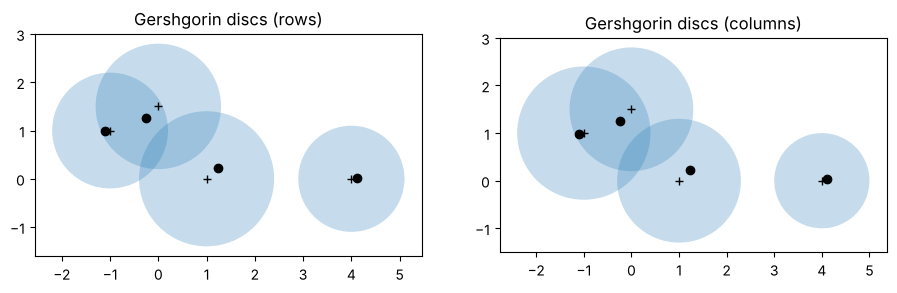

eps = 0.1: |mu - 1| = 0.01392,  8 eps^2 = 0.080,  1.5 eps^2 = 0.0150


In [6]:
from matplotlib.patches import Circle
M = np.array([[4, 0.6, 0.3, 0.2], [0.5, -1 + 1j, 0.4, 0.3], [0.3, 0.2, 1.5j, 0.8], [0.2, 0.6, 0.6, 1.0]], dtype=complex)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, Mat, title in [(axes[0], M, "rows"), (axes[1], M.T, "columns")]:
    for i in range(4):
        c = Mat[i, i]; r = np.abs(Mat[i]).sum() - abs(c)
        ax.add_patch(Circle((c.real, c.imag), r, alpha=0.25)); ax.plot(c.real, c.imag, "+k")
    ev = np.linalg.eigvals(Mat); ax.plot(ev.real, ev.imag, "ko")
    ax.set_aspect("equal"); ax.autoscale(); ax.set_title(f"Gershgorin discs ({title})")
plt.show()

eps = 0.1
A = np.array([[1, eps, eps], [eps, 2, eps], [eps, eps, 3]])
mu = np.linalg.eigvalsh(A).min()
print(f"eps = {eps}: |mu - 1| = {abs(mu - 1):.5f},  8 eps^2 = {8 * eps**2:.3f},  1.5 eps^2 = {1.5 * eps**2:.4f}")

The row discs and the column discs give different localisations; the eigenvalues lie in the intersection of the two unions. In the scaled example the true distance $0.014$ is close to the second-order prediction $1.5\varepsilon^2=0.015$, well inside the guaranteed $8\varepsilon^2=0.08$.

### P11.6
**How to find it.** `scipy.linalg.eigvalsh` with `subset_by_index` computes only the top eigenvalue. For Step 1, the weights are $p_n=(n+\frac12)^{-1/2}$.

N =    10: lambda_max = 1.751920,  pi - lambda_max = 1.3897
N =    30: lambda_max = 1.986493,  pi - lambda_max = 1.1551
N =   100: lambda_max = 2.182696,  pi - lambda_max = 0.9589
N =   300: lambda_max = 2.322020,  pi - lambda_max = 0.8196
N =  1000: lambda_max = 2.443152,  pi - lambda_max = 0.6984
N =  3000: lambda_max = 2.532132,  pi - lambda_max = 0.6095


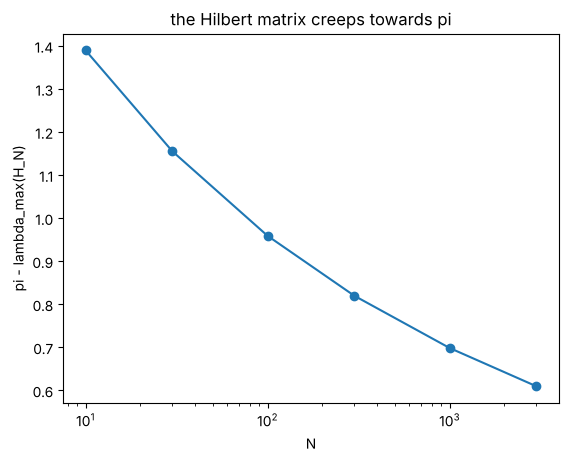

Schur test ratios sum_n k_mn p_n / p_m (truncated at N = 2e5): [2.2076 2.616  2.9387 3.0364 2.9812]  all < pi: True


In [7]:
Ns = [10, 30, 100, 300, 1000, 3000]; lams = []
for N in Ns:
    i = np.arange(N); H = 1.0 / (i[:, None] + i[None, :] + 1)
    lams.append(scipy.linalg.eigvalsh(H, subset_by_index=[N - 1, N - 1])[0])
for N, l in zip(Ns, lams):
    print(f"N = {N:5d}: lambda_max = {l:.6f},  pi - lambda_max = {math.pi - l:.4f}")
plt.semilogx(Ns, [math.pi - l for l in lams], "o-"); plt.xlabel("N"); plt.ylabel("pi - lambda_max(H_N)")
plt.title("the Hilbert matrix creeps towards pi"); plt.show()

N = 200000; n = np.arange(N); p = (n + 0.5) ** -0.5
ratios = [(p / (m + n + 1)).sum() / p[m] for m in [0, 1, 10, 100, 1000]]
print("Schur test ratios sum_n k_mn p_n / p_m (truncated at N = 2e5):", np.round(ratios, 4), " all < pi:", max(ratios) < math.pi)

The gap $\pi-\lambda_{\max}(H_N)$ decreases roughly linearly in $\log N$ on this range: it would take astronomically large $N$ to get close to $\pi$, in line with de Bruijn and Wilf's $\frac{\pi^5}{2\log^2N}$. The Schur test ratios are all below $\pi$, and approach it as $m$ grows (the truncation at $N$ terms lowers them slightly).